In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', None)
SEED = 42

In [3]:
data = pd.read_csv('dataset/reliabilityRisk2.csv')
print(data.shape)
print(data['Event'].value_counts(normalize=True).round(3))

missing_codes = pd.Series({
    'Gender = -1': (data['Gender'] == -1).sum(),
    'BP = -1': (data['BP'] == -1).sum(),
    'HearRate = -1': (data['HearRate'] == -1).sum(),
    'Albumine = 0': (data['Albumine'] == 0).sum(),
})
display(missing_codes)
display(data.describe().T.round(2))

(1469, 11)
Event
0    0.69
1    0.31
Name: proportion, dtype: float64


Gender = -1      28
BP = -1          19
HearRate = -1    17
Albumine = 0      1
dtype: int64

,count,mean,std,min,25%,50%,75%,max
Gender,1469.0,0.80,0.44,-1.0,1.00,1.00,1.00,1.00
Age,1469.0,67.95,13.23,30.0,58.00,70.00,78.00,101.00
BP,1469.0,138.12,33.73,-1.0,119.78,137.01,155.88,270.61
HearRate,1469.0,75.53,20.10,-1.0,64.00,74.00,86.00,180.00
STelevation,1469.0,0.04,0.19,0.0,0.00,0.00,0.00,1.00
Killip,1469.0,1.47,0.83,1.0,1.00,1.00,2.00,4.00
Albumine,1469.0,38.09,2.77,0.0,37.20,38.20,39.20,48.00
PCR,1469.0,2.62,8.49,0.0,0.50,0.70,1.90,263.00
Troponine,1469.0,47.40,104.04,0.0,1.58,10.20,43.00,1380.00
Creatinine,1469.0,137.71,134.91,24.7,81.00,97.50,135.10,1934.40


In [4]:
clean = data.copy()
clean[['Gender', 'BP', 'HearRate']] = clean[['Gender', 'BP', 'HearRate']].replace(-1, np.nan)
clean['Albumine'] = clean['Albumine'].replace(0, np.nan)

skewed = ['PCR', 'Troponine', 'Creatinine']
clean[skewed] = np.log1p(clean[skewed])

X = clean.drop(columns='Event')
y = clean['Event']
feature_names = list(X.columns)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(X_train.shape, X_test.shape, round(y_train.mean(), 3), round(y_test.mean(), 3))

(1175, 10) (294, 10) 0.311 0.31


In [5]:
prep = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])

candidates = {
    'Logistic regression': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'Random forest': RandomForestClassifier(n_estimators=500, min_samples_leaf=5, class_weight='balanced',
                                            random_state=SEED, n_jobs=-1),
    'KNN (k=31)': KNeighborsClassifier(n_neighbors=31),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for name, clf in candidates.items():
    scores = cross_validate(Pipeline([('prep', clone(prep)), ('clf', clone(clf))]), X_train, y_train, cv=cv,
                            scoring=['roc_auc', 'balanced_accuracy', 'accuracy'])
    rows.append({'Model': name,
                 'AUC': scores['test_roc_auc'].mean(),
                 'Balanced accuracy': scores['test_balanced_accuracy'].mean(),
                 'Accuracy': scores['test_accuracy'].mean()})
display(pd.DataFrame(rows).round(3).sort_values('AUC', ascending=False))

,Model,AUC,Balanced accuracy,Accuracy
0,Logistic regression,0.849,0.776,0.789
1,Random forest,0.842,0.775,0.784
2,KNN (k=31),0.839,0.721,0.801


In [6]:
model = Pipeline([('prep', clone(prep)), ('clf', clone(candidates['Logistic regression']))])
model.fit(X_train, y_train)

p_test = model.predict_proba(X_test)[:, 1]
y_hat_test = (p_test >= 0.5).astype(int)
correct = (y_hat_test == y_test.values).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, y_hat_test).ravel()
print(f'AUC = {roc_auc_score(y_test, p_test):.3f}')
print(f'Accuracy = {accuracy_score(y_test, y_hat_test):.3f}')
print(f'Balanced accuracy = {balanced_accuracy_score(y_test, y_hat_test):.3f}')
print(f'SE = {tp / (tp + fn):.3f}  SP = {tn / (tn + fp):.3f}')
display(pd.DataFrame([[tn, fp], [fn, tp]], index=['Y=0', 'Y=1'], columns=['Ŷ=0', 'Ŷ=1']))

AUC = 0.852
Accuracy = 0.806
Balanced accuracy = 0.787
SE = 0.736  SP = 0.837


,Ŷ=0,Ŷ=1
Y=0,170,33
Y=1,24,67


In [7]:
p_oof = cross_val_predict(clone(model), X_train, y_train, cv=cv, method='predict_proba')[:, 1]
y_hat_oof = (p_oof >= 0.5).astype(int)
y_tr = y_train.values
print(f'Accuracy out-of-fold no treino: {(y_hat_oof == y_tr).mean():.3f}')

scaler = clone(prep).fit(X_train)
Z_train = scaler.transform(X_train)
Z_test = scaler.transform(X_test)

Accuracy out-of-fold no treino: 0.789


In [8]:
def reliability_metrics(k=30):
    nn = NearestNeighbors(n_neighbors=k).fit(Z_train)
    dist_test, idx = nn.kneighbors(Z_test)

    # k + 1 porque o vizinho mais próximo de um ponto de treino é ele próprio
    dist_train, _ = NearestNeighbors(n_neighbors=k + 1).fit(Z_train).kneighbors(Z_train)
    mean_dist_train = dist_train[:, 1:].mean(axis=1)
    d_min, d_max = mean_dist_train.min(), np.percentile(mean_dist_train, 99)

    aed = 1 - np.clip((dist_test.mean(axis=1) - d_min) / (d_max - d_min), 0, 1)
    agreement = (y_hat_oof[idx] == y_tr[idx]).mean(axis=1)
    data_agreement = (y_tr[idx] == y_hat_test[:, None]).mean(axis=1)
    model_agreement = (y_hat_oof[idx] == y_hat_test[:, None]).mean(axis=1)
    combined = aed * data_agreement * model_agreement

    return pd.DataFrame({
        'Density (AED)': aed,
        'Local fit (agreement)': agreement,
        'Data agreement': data_agreement,
        'Model agreement': model_agreement,
        'Combined': combined,
        'Model confidence (baseline)': np.abs(p_test - 0.5) * 2,
    }, index=X_test.index)

K = 30
rel = reliability_metrics(K)
display(rel.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
Density (AED),294.0,0.690,0.235,0.000,0.559,0.747,0.889,0.991
Local fit (agreement),294.0,0.825,0.130,0.500,0.733,0.833,0.933,1.000
Data agreement,294.0,0.784,0.203,0.100,0.700,0.833,0.933,1.000
Model agreement,294.0,0.881,0.193,0.067,0.833,1.000,1.000,1.000
Combined,294.0,0.517,0.282,0.000,0.266,0.554,0.783,0.978
Model confidence (baseline),294.0,0.572,0.277,0.002,0.365,0.623,0.800,1.000


In [9]:
def evaluate_metrics(rel):
    rows = []
    for name in rel.columns:
        r = rel[name].values
        rows.append({'Metric': name,
                     'Pearson r (reliability, correct)': np.corrcoef(r, correct)[0, 1],
                     'AUC (reliability → correct)': roc_auc_score(correct, r)})
    return pd.DataFrame(rows).round(3).sort_values('AUC (reliability → correct)', ascending=False)

display(evaluate_metrics(rel))

,Metric,"Pearson r (reliability, correct)",AUC (reliability → correct)
2,Data agreement,0.381,0.762
1,Local fit (agreement),0.338,0.744
4,Combined,0.317,0.732
3,Model agreement,0.316,0.728
5,Model confidence (baseline),0.260,0.689
0,Density (AED),0.137,0.608


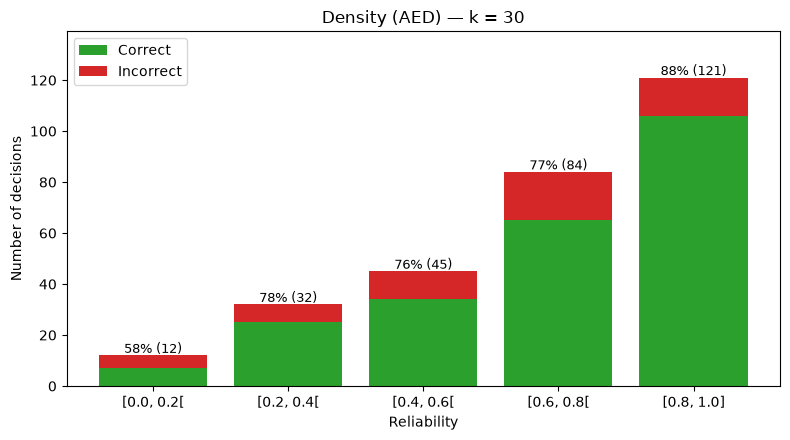

,Bin,N,Correct,Incorrect,% correct
0,"[0.0, 0.2[",12,7,5,58.3
1,"[0.2, 0.4[",32,25,7,78.1
2,"[0.4, 0.6[",45,34,11,75.6
3,"[0.6, 0.8[",84,65,19,77.4
4,"[0.8, 1.0]",121,106,15,87.6


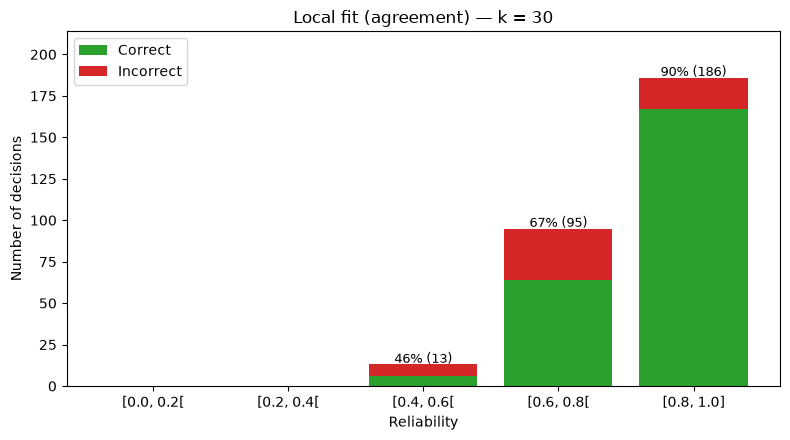

,Bin,N,Correct,Incorrect,% correct
0,"[0.0, 0.2[",0,0,0,NaN
1,"[0.2, 0.4[",0,0,0,NaN
2,"[0.4, 0.6[",13,6,7,46.2
3,"[0.6, 0.8[",95,64,31,67.4
4,"[0.8, 1.0]",186,167,19,89.8


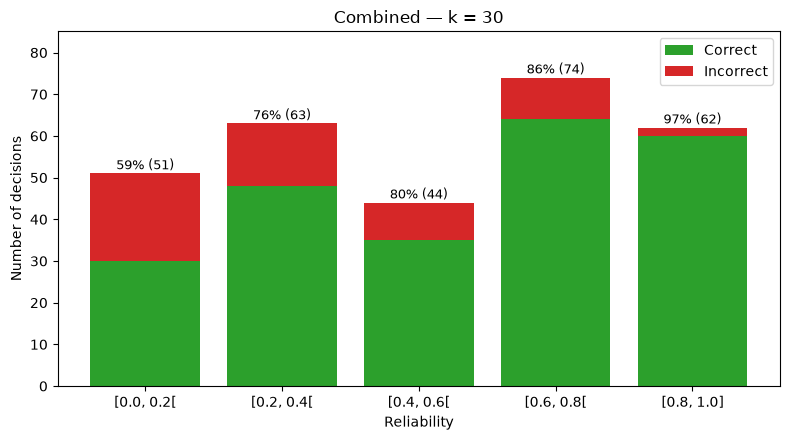

,Bin,N,Correct,Incorrect,% correct
0,"[0.0, 0.2[",51,30,21,58.8
1,"[0.2, 0.4[",63,48,15,76.2
2,"[0.4, 0.6[",44,35,9,79.5
3,"[0.6, 0.8[",74,64,10,86.5
4,"[0.8, 1.0]",62,60,2,96.8


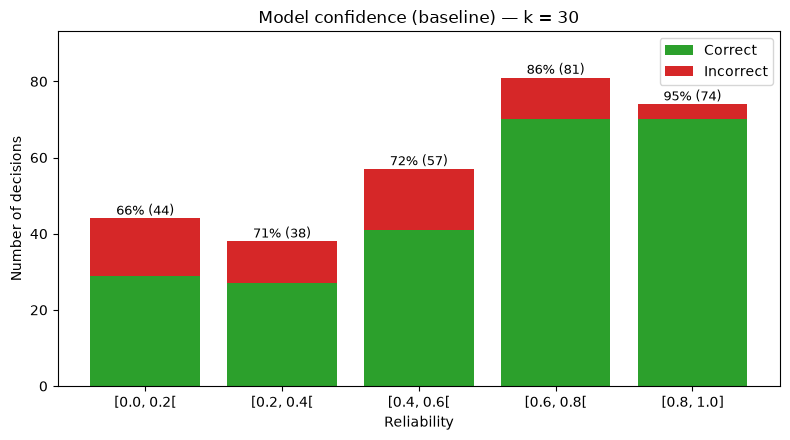

,Bin,N,Correct,Incorrect,% correct
0,"[0.0, 0.2[",44,29,15,65.9
1,"[0.2, 0.4[",38,27,11,71.1
2,"[0.4, 0.6[",57,41,16,71.9
3,"[0.6, 0.8[",81,70,11,86.4
4,"[0.8, 1.0]",74,70,4,94.6


In [10]:
BIN_EDGES = np.array([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
BIN_LABELS = ['[0.0, 0.2[', '[0.2, 0.4[', '[0.4, 0.6[', '[0.6, 0.8[', '[0.8, 1.0]']

def reliability_table(scores, correct):
    bins = np.clip(np.digitize(scores, BIN_EDGES) - 1, 0, len(BIN_LABELS) - 1)
    rows = []
    for b, label in enumerate(BIN_LABELS):
        mask = bins == b
        n = mask.sum()
        n_correct = correct[mask].sum()
        rows.append({'Bin': label, 'N': n, 'Correct': n_correct, 'Incorrect': n - n_correct,
                     '% correct': round(100 * n_correct / n, 1) if n else np.nan})
    return pd.DataFrame(rows)

def plot_reliability(scores, correct, title, fname):
    table = reliability_table(scores, correct)
    x = np.arange(len(table))
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.bar(x, table['Correct'], color='tab:green', label='Correct')
    ax.bar(x, table['Incorrect'], bottom=table['Correct'], color='tab:red', label='Incorrect')
    for i, row in table.iterrows():
        if row['N'] > 0:
            ax.text(i, row['N'] + 1, f"{row['% correct']:.0f}% ({row['N']})", ha='center', fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels(table['Bin'])
    ax.set_ylim(0, table['N'].max() * 1.15)
    ax.set_xlabel('Reliability')
    ax.set_ylabel('Number of decisions')
    ax.set_title(title)
    ax.legend()
    plt.tight_layout()
    plt.savefig(fname, dpi=150)
    plt.show()
    return table

for name, fname in [('Density (AED)', 'rel_density.png'),
                    ('Local fit (agreement)', 'rel_local_fit.png'),
                    ('Combined', 'rel_combined.png'),
                    ('Model confidence (baseline)', 'rel_baseline.png')]:
    display(plot_reliability(rel[name].values, correct, f'{name} — k = {K}', fname))

,Threshold,Coverage,Accuracy,Balanced accuracy,Predicted events,Real events,Sent to review
0,0.0,1.000,0.806,0.787,100,91,0
1,0.2,0.827,0.852,0.792,57,63,51
2,0.4,0.612,0.883,0.677,13,30,114
3,0.6,0.463,0.912,0.500,0,12,158
4,0.8,0.211,0.968,0.500,0,2,232


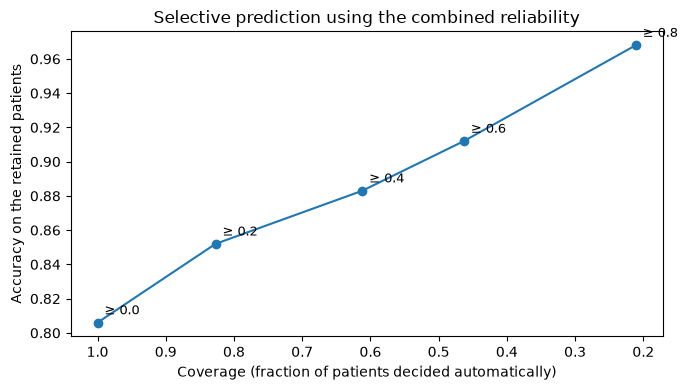

In [11]:
def selective_curve(scores, correct, y_true, y_pred):
    rows = []
    for threshold in [0.0, 0.2, 0.4, 0.6, 0.8]:
        mask = scores >= threshold
        rows.append({'Threshold': threshold,
                     'Coverage': mask.mean(),
                     'Accuracy': correct[mask].mean() if mask.any() else np.nan,
                     'Balanced accuracy': balanced_accuracy_score(y_true[mask], y_pred[mask])
                     if mask.any() and len(np.unique(y_true[mask])) > 1 else np.nan,
                     'Predicted events': y_pred[mask].sum(),
                     'Real events': y_true[mask].sum(),
                     'Sent to review': (~mask).sum()})
    return pd.DataFrame(rows).round(3)

selective = selective_curve(rel['Combined'].values, correct, y_test.values, y_hat_test)
display(selective)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(selective['Coverage'], selective['Accuracy'], marker='o')
for _, row in selective.iterrows():
    ax.annotate(f"≥ {row['Threshold']:.1f}", (row['Coverage'], row['Accuracy']),
                textcoords='offset points', xytext=(5, 6), fontsize=9)
ax.set_xlabel('Coverage (fraction of patients decided automatically)')
ax.set_ylabel('Accuracy on the retained patients')
ax.set_title('Selective prediction using the combined reliability')
ax.invert_xaxis()
plt.tight_layout()
plt.savefig('rel_selective.png', dpi=150)
plt.show()

In [12]:
examples = pd.concat([X_test, y_test], axis=1).copy()
examples[skewed] = np.expm1(examples[skewed])
examples['P(Event)'] = p_test.round(3)
examples['Prediction'] = y_hat_test
examples['Correct'] = correct
examples = examples.join(rel[['Density (AED)', 'Local fit (agreement)', 'Combined']].round(3))

order = rel['Combined'].sort_values().index
display(examples.loc[order[:3]].round(2).T)
display(examples.loc[order[-3:]].round(2).T)

,1405,1302,421
Gender,1.00,1.00,1.00
Age,90.00,62.00,72.00
BP,141.00,89.82,222.80
HearRate,61.00,54.00,60.00
STelevation,1.00,0.00,1.00
Killip,2.00,2.00,3.00
Albumine,31.00,20.00,39.00
PCR,16.10,11.40,0.50
Troponine,0.03,35.30,37.80
Creatinine,236.50,294.80,316.80


,811,642,679
Gender,1.00,1.00,1.00
Age,61.00,66.00,60.00
BP,134.40,159.87,152.20
HearRate,70.00,72.00,62.00
STelevation,0.00,0.00,0.00
Killip,1.00,1.00,1.00
Albumine,36.00,37.20,36.60
PCR,0.50,0.50,0.50
Troponine,1.72,0.20,0.95
Creatinine,74.20,95.00,78.90
